In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']

listings = pd.read_csv('data/listings_clean.csv', parse_dates=date_columns)

print(listings.shape)


(4574, 73)


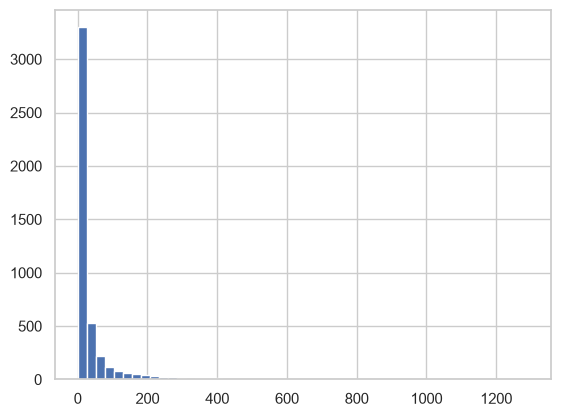

In [5]:
fig, ax = plt.subplots()

# ax = axes

ax.hist(listings['number_of_reviews'].dropna(), bins=50)

plt.show()

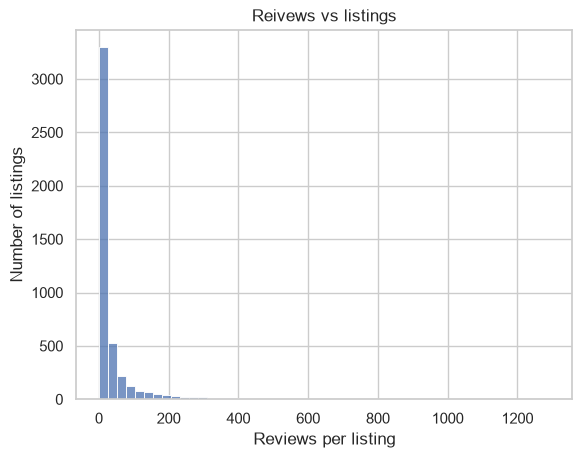

In [7]:
fig, ax = plt.subplots()

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.set_title('Reivews vs listings')
ax.set_xlabel('Reviews per listing')
ax.set_ylabel('Number of listings')

plt.show()

clearer

In [9]:
q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)

listings['reviews_outlier'] = listings['number_of_reviews'] > upper

print(round(upper, 1), listings['reviews_outlier'].sum())

69.5 582


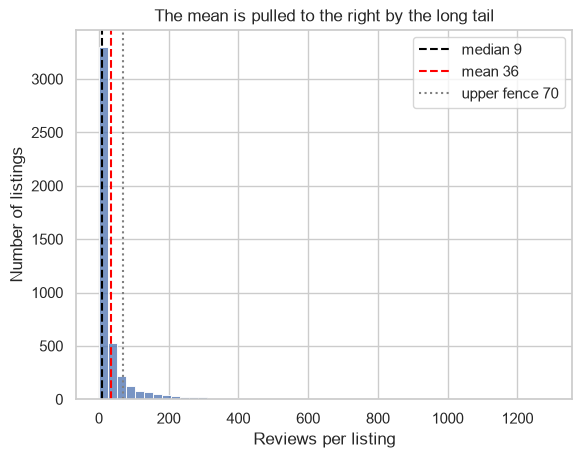

In [11]:
median = listings['number_of_reviews'].median()
mean = listings['number_of_reviews'].mean()

fig, ax = plt.subplots()

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.axvline(median, color='black', linestyle='--', label=f'median {median:,.0f}')
ax.axvline(mean, color='red', linestyle='--', label=f'mean {mean:,.0f}')
ax.axvline(upper, color='gray', linestyle=':', label=f'upper fence {upper:,.0f}')


ax.set_title('The mean is pulled to the right by the long tail')
ax.set_xlabel('Reviews per listing')
ax.set_ylabel('Number of listings')
ax.legend()

plt.show()
